# 11 · Launchers, datasets and training

Three ways to use the generator:

1. **offline datasets**: `python -m nxgen.cli.generate` writes an nnU-Net v2 raw dataset;
2. **during training**: `nxgen.training.SyntheticStream` feeds a torch `DataLoader`;
3. **from Python**: `Generator(...)(seed)` (notebooks 00 and 10).

This notebook covers 1 and 2, plus reproducibility.

In [1]:
from _setup import *
import json, subprocess, time
ensure_template()
PY = sys.executable

## 1. The offline launcher (templates)

```bash
python -m nxgen.cli.build_templates --config CONFIG (--seg MAP [MAP ...] | --seg-dir DIR) \
       --out DIR [--device cpu] [--overwrite]
```

It reads `template.*` and `labels.*` from the config (notebook 03). Every launcher option:

In [2]:
print(subprocess.run([PY, '-m', 'nxgen.cli.build_templates', '--help'], cwd=ROOT,
                     capture_output=True, text=True).stdout)

usage: build_templates.py [-h] --config CONFIG
                          (--seg SEG [SEG ...] | --seg-dir SEG_DIR) --out OUT
                          [--device DEVICE] [--overwrite]

Offline launcher: build HR templates from label maps.

options:
  -h, --help           show this help message and exit
  --config CONFIG      config JSON
  --seg SEG [SEG ...]  label map(s) (.nii/.nii.gz)
  --seg-dir SEG_DIR    folder of label maps (*.nii.gz)
  --out OUT            output folder
  --device DEVICE      device of the super-resolution (default 'cpu': large maps need a lot of memory)
  --overwrite          rebuild even if a matching template exists



## 2. The online launcher (datasets)

In [3]:
print(subprocess.run([PY, '-m', 'nxgen.cli.generate', '--help'], cwd=ROOT,
                     capture_output=True, text=True).stdout)

usage: generate.py [-h] --templates TEMPLATES [TEMPLATES ...] --config CONFIG
                   -n N --out OUT [--dataset-id DATASET_ID]
                   [--dataset-name DATASET_NAME] [--prefix PREFIX]
                   [--seed SEED] [--start START] [--device DEVICE]
                   [--overwrite] [--save-steps SAVE_STEPS [SAVE_STEPS ...]]
                   [--profile]

Online launcher: write synthetic images as an nnU-Net v2 raw dataset.

options:
  -h, --help            show this help message and exit
  --templates TEMPLATES [TEMPLATES ...]
                        HR template files, or folders of *.nii.gz
  --config CONFIG       config JSON
  -n N                  number of images
  --out OUT             output root folder
  --dataset-id DATASET_ID
  --dataset-name DATASET_NAME
  --prefix PREFIX       case name prefix
  --seed SEED           run seed
  --start START         first image index
  --device DEVICE
  --overwrite           regenerate cases that already exist
  --save

Generate 3 full-volume images, with the steps of the images saved and profiling on:

In [4]:
out = os.path.join(OUTPUTS, 'datasets')
cmd = [PY, '-m', 'nxgen.cli.generate', '--templates', TEMPLATE_DIR, '--config', CONFIG,
       '-n', '3', '--out', out, '--dataset-id', '901', '--dataset-name', 'NotebookDemo',
       '--device', DEVICE, '--overwrite', '--save-steps', 'pv_seg', 'synthesis', 'image']
r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-3000:], r.stderr[-2000:])

synth_00000: [239, 439, 289] voxels, acquisition none [0.4, 0.4, 0.4] mm, 263 generation classes
synth_00001: [239, 439, 289] voxels, acquisition none [0.4, 0.4, 0.4] mm, 263 generation classes
synth_00002: [239, 439, 289] voxels, acquisition none [0.4, 0.4, 0.4] mm, 263 generation classes
 


## 3. The dataset layout

```
Dataset901_NotebookDemo/
  imagesTr/<prefix>_<i>_0000.nii.gz   image, float32 (5-digit index)
  labelsTr/<prefix>_<i>.nii.gz        segmentation, label indices, uint16
  plans/<prefix>_<i>.json             the plan + normalisation values (+ timings with --profile)
  steps/<prefix>_<i>/                 intermediate steps (--save-steps)
  label_space.json                    index <-> raw value and name (frozen at the first run)
  configs/<hash>/config.json, tree.json    every config used in the dataset
  dataset.json                        nnU-Net v2 description
```

In [5]:
root = os.path.join(out, 'Dataset901_NotebookDemo')
for dirpath, dirs, files in sorted(os.walk(root)):
    depth = dirpath[len(root):].count(os.sep)
    print('  ' * depth + os.path.basename(dirpath) + '/')
    for f in sorted(files)[:4]:
        print('  ' * (depth + 1) + f)
    if len(files) > 4:
        print('  ' * (depth + 1) + f'... {len(files) - 4} more')

Dataset901_NotebookDemo/
  dataset.json
  label_space.json
  configs/
    612a035fc7/
      config.json
      tree.json
  imagesTr/
    synth_00000_0000.nii.gz
    synth_00001_0000.nii.gz
    synth_00002_0000.nii.gz
  labelsTr/
    synth_00000.nii.gz
    synth_00001.nii.gz
    synth_00002.nii.gz
  plans/
    synth_00000.json
    synth_00001.json
    synth_00002.json
  steps/
    synth_00000/
      01_pv_seg.nii.gz
      02_synthesis.nii.gz
      03_image.nii.gz
    synth_00001/
      01_pv_seg.nii.gz
      02_synthesis.nii.gz
      03_image.nii.gz
    synth_00002/
      01_pv_seg.nii.gz
      02_synthesis.nii.gz
      03_image.nii.gz


In [6]:
ds = json.load(open(os.path.join(root, 'dataset.json')))
print({k: (v if k != 'labels' and k != 'original_label_values' else f'<{len(v)} entries>') for k, v in ds.items()})
print('first labels:', list(ds['labels'].items())[:4])
spec = json.load(open(os.path.join(root, 'plans', 'synth_00000.json')))
print('plan file keys:', list(spec), '| plan keys:', list(spec['plan']))

{'channel_names': {'0': 'synthetic'}, 'labels': '<300 entries>', 'numTraining': 3, 'file_ending': '.nii.gz', 'original_label_values': '<300 entries>'}
first labels: [('background', 0), ('white_matter_of_forebrain', 1), ('head_of_caudate', 2), ('anterior_horn_of_lateral_ventricle', 3)]
plan file keys: ['case', 'run_seed', 'index', 'plan', 'normalization', 'timings'] | plan keys: ['version', 'seed', 'config_hash', 'template', 'template_path', 'roi', 'acquisition', 'morphology', 'spatial', 'tree', 'bias', 'motion', 'noise']


* `labels` maps each **name** to its **index** (what nnU-Net reads); `original_label_values`
  gives the raw NextBrain value of each index.
* The plan file of each image says everything about it, including the hash of its config
  (`plan.config_hash` → `configs/<hash>/`).

## 4. Resuming, extending, regenerating

* **Resume**: run the same command again; cases whose image, label and plan all exist are
  skipped.
* **Extend**: `--start 3 -n 10` adds images 3..12 to the same dataset.
* **Regenerate image i**: `--start i -n 1 --overwrite` (same run seed → same image seed).
* The label space is read from `label_space.json`, so indices do not change between runs, even
  with other templates.

In [7]:
r = subprocess.run(cmd[:cmd.index('--overwrite')], cwd=ROOT, capture_output=True, text=True)
print(r.stdout)

synth_00000: exists, skipped
synth_00001: exists, skipped
synth_00002: exists, skipped



Regenerating one image gives the same segmentation:

In [8]:
from nxgen.core.io import load_labels
before, _, _ = load_labels(os.path.join(root, 'labelsTr', 'synth_00001.nii.gz'))
cmd1 = cmd[:cmd.index('-n')] + ['-n', '1', '--start', '1'] + cmd[cmd.index('--out'):cmd.index('--save-steps')]
subprocess.run(cmd1, cwd=ROOT, capture_output=True, text=True)
after, _, _ = load_labels(os.path.join(root, 'labelsTr', 'synth_00001.nii.gz'))
print('regenerated segmentation identical:', np.array_equal(before, after))

regenerated segmentation identical: True


## 5. Training: `SyntheticStream`

For training, images are generated on the fly, as patches, on the GPU:

```python
gen = Generator(templates, 'configs/nextbrain_patch.json', device='cuda:0')
loader = DataLoader(SyntheticStream(gen, run_seed=0), batch_size=2, num_workers=0)
for image, seg in loader:          # (B, 1, X, Y, Z) float32, (B, 1, X, Y, Z) int64
    ...
```

* sample `i` of the stream uses `image_seed(run_seed, start + i)`: a training run is reproducible
  and any sample can be regenerated alone;
* **CUDA generation needs `num_workers=0`** (CUDA cannot be used in forked worker processes).
  Generation then runs in the training process. To use another GPU for generation, build the
  Generator on it and set `out_device` to the training GPU;
* with a CPU generator, workers are fine: each worker takes every `num_workers`-th index;
* `return_plan=True` also yields the plan (e.g. to read `class_of` for the loss).

batch: (2, 1, 160, 160, 160) torch.float32 | (2, 1, 160, 160, 160) torch.int64 | cuda:3
0.144 s per batch of 2 -> 0.072 s per sample


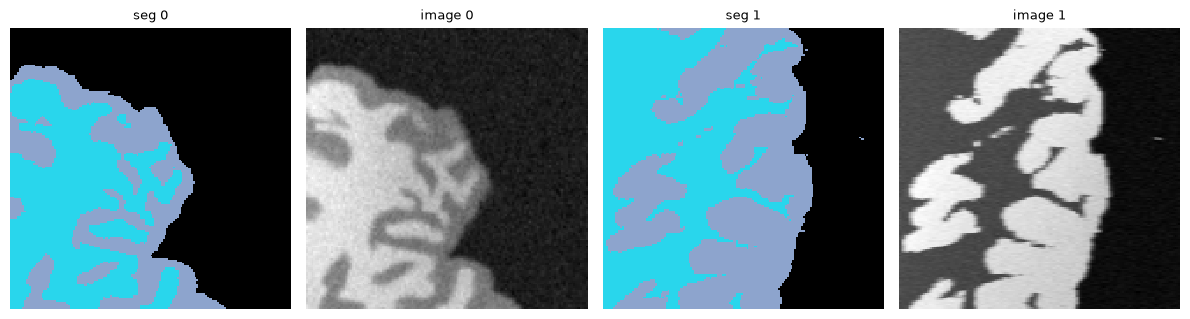

In [9]:
from torch.utils.data import DataLoader
from nxgen import Generator
from nxgen.training import SyntheticStream

pgen = Generator([TEMPLATE], CONFIG_PATCH, device=DEVICE)
loader = DataLoader(SyntheticStream(pgen, run_seed=0), batch_size=2, num_workers=0)
it = iter(loader)
next(it)                                                   # warm-up
t0 = time.perf_counter()
for step in range(5):
    image, seg = next(it)
if DEVICE.startswith('cuda'):
    torch.cuda.synchronize(DEVICE)
dt = (time.perf_counter() - t0) / 5
print('batch:', tuple(image.shape), image.dtype, '|', tuple(seg.shape), seg.dtype, '|', image.device)
print(f'{dt:.3f} s per batch of 2 -> {dt / 2:.3f} s per sample')
show([seg[0, 0], image[0, 0], seg[1, 0], image[1, 0]], ['seg 0', 'image 0', 'seg 1', 'image 1'],
     labels=[True, False, True, False])

Plans with the batch, e.g. for a loss that merges the generation classes:

In [10]:
stream = SyntheticStream(pgen, run_seed=0, return_plan=True)
image, seg, plan = next(iter(stream))
print(tuple(image.shape), '| classes in this sample:', len(plan['tree']['class_names']),
      '| class_of[:10] =', plan['tree']['class_of'][:10])

(1, 160, 160, 160) | classes in this sample: 263 | class_of[:10] = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 6. Reproducibility, in short

| what | how |
|---|---|
| image `i` of a run | `image_seed(run_seed, i)` → same plan |
| a saved image | its plan file (`plans/<case>.json`) → `gen.render(plan)` |
| the exact settings | `configs/<hash>/` of the dataset |
| the exact template | the template build record (source SHA-256 + settings) |
| the label indices | `label_space.json` of the dataset |

Segmentations are reproduced exactly. Images can differ by floating-point rounding on the GPU,
and between CPU and GPU (different random generators for the voxel noise).

In [11]:
from nxgen.core.rng import image_seed
from nxgen.core.io import load_json
plan = load_json(os.path.join(root, 'plans', 'synth_00002.json'))['plan']
gen = Generator([TEMPLATE], CONFIG, device=DEVICE)
again = gen.render(plan)
saved, _, _ = load_labels(os.path.join(root, 'labelsTr', 'synth_00002.nii.gz'))
print('seed in plan == image_seed(0, 2):', plan['seed'] == image_seed(0, 2))
print('replayed segmentation == saved  :', np.array_equal(again.seg.cpu().numpy(), saved))

seed in plan == image_seed(0, 2): True
replayed segmentation == saved  : True
